# Autoencoder Comparison

This notebook compares **LSTM-AE, CNN-LSTM-AE, and Transformer-AE** using normal-flight data. Anomaly scores are calculated from reconstruction error and evaluated using **AUROC, AUPRC, and separation ratio**.

# 1. Imports

In [2]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score
import joblib
import gc
import time
 
print(f"PyTorch : {torch.__version__}")
device = torch.device(
    "mps"  if torch.backends.mps.is_available()  else
    "cuda" if torch.cuda.is_available()           else
    "cpu"
)
print(f"Device  : {device}")
 

PyTorch : 2.12.1
Device  : mps


# 2. Paths & config

In [3]:
PROJECT_DIR  = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
DATA_VERSION = "v5_voltage_kfold5"
DATA_ROOT    = PROJECT_DIR / "processed_10hz" / "v2"
OUTPUT_DIR   = PROJECT_DIR / "model_outputs" / "v2" / "05_ae_comparison"
PLOT_DIR     = OUTPUT_DIR / "plots"
 
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
 
TARGET_COL = "target_energy_next_60s_wh"
ID_COLS    = ["log_id", "dataset_label"]
FOLDS      = ["fold_01", "fold_02", "fold_03", "fold_04", "fold_05"]

# 3. training config

In [4]:
SEQ_LEN       = 100
STRIDE_TRAIN  = 20
STRIDE_SCORE  = 10
BATCH_SIZE    = 64
MAX_EPOCHS    = 200
PATIENCE      = 15
LR            = 1e-3
MAX_GRAD_NORM = 1.0
THRESHOLD_PCT = 95
 
print(f"Data root  : {DATA_ROOT}")
print(f"Output     : {OUTPUT_DIR}")
print(f"Window     : {SEQ_LEN} rows ({SEQ_LEN/10:.0f}s at 10Hz)")
print(f"Folds      : {FOLDS}")

Data root  : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/v2
Output     : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/v2/05_ae_comparison
Window     : 100 rows (10s at 10Hz)
Folds      : ['fold_01', 'fold_02', 'fold_03', 'fold_04', 'fold_05']


# 4. Data loading

In [5]:
def load_fold_scaled(fold_name: str):
    """Load scaled train/val/test parquets for one fold."""
    fold_dir = DATA_ROOT / fold_name
    base     = f"no_dr_scaled_{DATA_VERSION}_{fold_name}"
    train_df = pd.read_parquet(fold_dir / f"train_{base}.parquet")
    val_df   = pd.read_parquet(fold_dir / f"val_{base}.parquet")
    test_df  = pd.read_parquet(fold_dir / f"test_{base}.parquet")
    return train_df, val_df, test_df
    
# quick check
_t, _v, _te = load_fold_scaled("fold_01")
feature_cols = [
    c for c in _t.columns
    if c not in ID_COLS + [TARGET_COL]
    and pd.api.types.is_numeric_dtype(_t[c])
]
N_FEATURES = len(feature_cols)
print(f"\nFold 01: train {_t.shape}  val {_v.shape}  test {_te.shape}")
print(f"Features ({N_FEATURES}): {feature_cols}")
del _t, _v, _te


Fold 01: train (665216, 19)  val (110878, 19)  test (190831, 19)
Features (16): ['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'is_idle', 'power_w_rolling_std_3s', 'voltage_per_cell', 'voltage_filtered_per_cell', 'voltage_per_cell_suspicious']


# 5. Windowing helpers

In [6]:
 
def prepare_sorted(df):
    """Sort by flight then time — ensures windows never cross flight boundaries."""
    df = df.copy()
    df["log_id"] = df["log_id"].astype(str)
    return df.sort_values(["log_id", "time_s"]).reset_index(drop=True)
 
 
def build_window_starts(df, seq_len, stride, normal_only=False):
    """
    Build array of window start indices, per flight.
    normal_only=True → only include flights labelled 'normal' (for training).
    """
    starts = []
    for log_id, grp in df.groupby("log_id", sort=False):
        idxs = grp.index.to_numpy()
        if len(idxs) < seq_len:
            continue
        if normal_only and grp["dataset_label"].iloc[0] != "normal":
            continue
        for offset in range(0, len(idxs) - seq_len + 1, stride):
            starts.append(idxs[offset])
    return np.array(starts, dtype=np.int64)
 
 
class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, starts, seq_len):
        self.arr, self.starts, self.seq_len = arr, starts, seq_len
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        return torch.tensor(self.arr[s:s+self.seq_len], dtype=torch.float32)
 
 
class ScoringDataset(torch.utils.data.Dataset):
    """Returns (window_tensor, start_index) for score accumulation."""
    def __init__(self, arr, starts, seq_len):
        self.arr, self.starts, self.seq_len = arr, starts, seq_len
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        return torch.tensor(self.arr[s:s+self.seq_len], dtype=torch.float32), s
 
 

# 6. LSTM Autoencoder

<div style="font-size: 13px; line-height: 1.5;">

**Configuration:** `hidden_size=64`, `latent_size=32`, `num_layers=2`, `dropout=0.2`

**Justification:**  
The configuration was based on Reis and Reis (2025) and Malhotra et al. (2016). Two LSTM layers were used to capture temporal patterns, while the hidden and latent sizes were kept moderate to reduce model complexity.

</div>

In [7]:

class LSTMAutoencoder(nn.Module):
    """
    LSTM Autoencoder — primary baseline architecture.
 
    Encoder: 2-layer LSTM → linear bottleneck (latent_size)
    Decoder: latent → initialised h0/c0 → 2-layer LSTM → output projection
 
    Using h0/c0 initialisation from latent (vs simple input repeat) improves
    gradient flow through the decoder and produces sharper reconstruction
    boundaries between normal and abnormal sequences.
    """
    def __init__(self, n_features, hidden_size=64, latent_size=32,
                 n_layers=2, dropout=0.2):
        super().__init__()
        self.n_layers    = n_layers
        self.hidden_size = hidden_size
 
        self.encoder_lstm = nn.LSTM(
            n_features, hidden_size, num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )
        self.encoder_fc   = nn.Linear(hidden_size, latent_size)
 
        # initialise decoder hidden and cell state from latent
        self.decoder_h0_fc  = nn.Linear(latent_size, hidden_size)
        self.decoder_c0_fc  = nn.Linear(latent_size, hidden_size)
        self.decoder_input_fc = nn.Linear(latent_size, hidden_size)
 
        self.decoder_lstm = nn.LSTM(
            hidden_size, hidden_size, num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )
        self.output_fc = nn.Linear(hidden_size, n_features)
 
    def forward(self, x):
        # encode
        _, (h, c) = self.encoder_lstm(x)
        latent    = self.encoder_fc(h[-1])          # (batch, latent)
 
        # initialise decoder state from latent
        h0 = self.decoder_h0_fc(latent).unsqueeze(0).repeat(self.n_layers, 1, 1)
        c0 = self.decoder_c0_fc(latent).unsqueeze(0).repeat(self.n_layers, 1, 1)
 
        # decode — repeat latent input across sequence
        dec_in     = self.decoder_input_fc(latent).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.decoder_lstm(dec_in, (h0, c0))
        return self.output_fc(dec_out)
 

# 7. CNN-LSTM Autoencoder

<div style="font-size: 13px; line-height: 1.5;">

**Configuration:** `cnn_channels=32`, `lstm_hidden=64`, `latent_size=32`, `kernel_size=3`, `dropout=0.2`

**Justification:**  
Two Conv1D layers extract local patterns, while the LSTM captures temporal behaviour. The configuration was based on Radaideh et al. (2022), Bai et al. (2018), and Zhang and Zhou (2023).

</div>

In [8]:

class CNNLSTMAutoencoder(nn.Module):
    """
    CNN-LSTM Autoencoder.
 
    Encoder: Conv1D(32, k=3) → ReLU → Conv1D(64, k=3) → ReLU
             → LSTM(64) → linear bottleneck(32)
    Decoder: latent → h0/c0 init → LSTM(64) → linear output
 
    The CNN layers extract local temporal patterns (e.g., short voltage spikes,
    current transients) before the LSTM captures longer-range dependencies.
    This two-stage approach is particularly suited to battery telemetry where
    both short-term signal noise and long-term discharge patterns are relevant.
    """
    def __init__(self, n_features, cnn_channels=32, lstm_hidden=64,
                 latent_size=32, kernel_size=3, dropout=0.2):
        super().__init__()
 
        # progressive CNN encoder: 32 → 64 channels
        self.cnn_encoder = nn.Sequential(
            nn.Conv1d(n_features, cnn_channels, kernel_size=kernel_size, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(cnn_channels, cnn_channels * 2, kernel_size=kernel_size, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
 
        self.lstm_encoder   = nn.LSTM(cnn_channels * 2, lstm_hidden,
                                       batch_first=True, dropout=0.0)
        self.latent_fc      = nn.Linear(lstm_hidden, latent_size)
 
        self.decoder_h0_fc  = nn.Linear(latent_size, lstm_hidden)
        self.decoder_c0_fc  = nn.Linear(latent_size, lstm_hidden)
        self.decoder_input_fc = nn.Linear(latent_size, lstm_hidden)
        self.lstm_decoder   = nn.LSTM(lstm_hidden, lstm_hidden, batch_first=True)
        self.output_fc      = nn.Linear(lstm_hidden, n_features)
 
    def forward(self, x):
        # x: (batch, seq_len, n_features)
        # CNN expects (batch, channels, seq_len)
        cnn_out    = self.cnn_encoder(x.transpose(1, 2)).transpose(1, 2)
        _, (h, _)  = self.lstm_encoder(cnn_out)
        latent     = self.latent_fc(h[-1])
 
        h0 = self.decoder_h0_fc(latent).unsqueeze(0)
        c0 = self.decoder_c0_fc(latent).unsqueeze(0)
        dec_in     = self.decoder_input_fc(latent).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.lstm_decoder(dec_in, (h0, c0))
        return self.output_fc(dec_out)
 
 

# 8. Transformer Autoencoder

<div style="font-size: 13px; line-height: 1.5;">

**Configuration:** `d_model=64`, `nhead=4`, `num_layers=2`, `dropout=0.1`, `dim_feedforward=256`

**Justification:**  
The architecture was scaled down for the smaller 16-feature dataset. Four attention heads divide the 64-dimensional embedding evenly, while the feedforward size follows the standard `4 × d_model` setting. A lower learning rate of `1e-4` was used for stable Transformer training.

</div>

In [9]:

class TransformerAutoencoder(nn.Module):
    """
    Transformer Autoencoder for multivariate time-series anomaly detection.
 
    Architecture:
        Input projection: n_features → d_model (linear)
        Positional encoding: learned parameter (seq_len × d_model)
        Encoder: num_layers × TransformerEncoderLayer(d_model, nhead)
        Output projection: d_model → n_features (linear)
 
    This is a reconstruction-based Transformer: the encoder reads the full
    sequence and reconstructs it. Anomaly score = per-timestep MSE, averaged
    across the window. Unlike the Anomaly Transformer (Xu et al. 2022) which
    uses association discrepancy, this implementation uses standard MSE
    reconstruction error for consistency with the LSTM-AE and CNN-LSTM-AE
    comparisons in this notebook.
    """
    def __init__(self, n_features, d_model=64, nhead=4, num_layers=2,
                 dropout=0.1, dim_feedforward=256, max_seq_len=200):
        super().__init__()
        assert d_model % nhead == 0, \
            f"d_model ({d_model}) must be divisible by nhead ({nhead})"
 
        self.input_proj    = nn.Linear(n_features, d_model)
        # learned positional encoding — Wang et al. (2024) ICONIP
        self.pos_encoding  = nn.Parameter(
            torch.randn(1, max_seq_len, d_model) * 0.02
        )
 
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,   # 4 × d_model — Vaswani et al. 2017
            dropout=dropout,
            batch_first=True,
            norm_first=True    # pre-norm for stability (Wang et al. 2022)
        )
        self.transformer  = nn.TransformerEncoder(encoder_layer,
                                                   num_layers=num_layers,
                                          enable_nested_tensor=False)
        self.output_proj  = nn.Linear(d_model, n_features)
 
    def forward(self, x):
        seq_len = x.size(1)
        x = self.input_proj(x) + self.pos_encoding[:, :seq_len, :]
        x = self.transformer(x)
        return self.output_proj(x)
 
 
# parameter count check
_models = {
    "LSTM-AE":        LSTMAutoencoder(N_FEATURES),
    "CNN-LSTM-AE":    CNNLSTMAutoencoder(N_FEATURES),
    "Transformer-AE": TransformerAutoencoder(N_FEATURES),
}
print("\nParameter counts:")
for name, m in _models.items():
    print(f"  {name:<20}: {sum(p.numel() for p in m.parameters()):>8,}")
del _models
 


Parameter counts:
  LSTM-AE             :  130,288
  CNN-LSTM-AE         :   83,792
  Transformer-AE      :  114,896


# 9. Training & scoring helpers

In [10]:

def train_one_model(model, train_loader, val_loader,
                    max_epochs=MAX_EPOCHS, patience=PATIENCE,
                    lr=LR, fold_name="", model_name="",
                    save_path=None):
    """
    Train model on normal-only windows with early stopping on val loss.
 
    Returns
    -------
    model        : trained nn.Module with best weights restored
    best_val_loss: float
    train_losses : list
    val_losses   : list
    best_epoch   : int
    """
    model      = model.to(device)
    optimiser  = torch.optim.Adam(model.parameters(), lr=lr)
    criterion  = nn.MSELoss()
    best_val   = float("inf")
    no_improve = 0
    best_state = None
    best_epoch = 0
    train_losses, val_losses = [], []
 
    for epoch in range(1, max_epochs + 1):
        # ── train
        model.train()
        t_loss = 0.0
        for xb in train_loader:
            xb = xb.to(device)
            optimiser.zero_grad()
            loss = criterion(model(xb), xb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            optimiser.step()
            t_loss += loss.item() * len(xb)
        t_loss /= len(train_loader.dataset)
 
        # ── validate
        model.eval()
        v_loss = 0.0
        with torch.no_grad():
            for xb in val_loader:
                xb     = xb.to(device)
                v_loss += criterion(model(xb), xb).item() * len(xb)
        v_loss /= len(val_loader.dataset)
 
        train_losses.append(t_loss)
        val_losses.append(v_loss)
 
        if epoch % 20 == 0 or epoch == 1:
            print(f"    Epoch {epoch:3d}/{max_epochs} — "
                  f"train: {t_loss:.6f}  val: {v_loss:.6f}  "
                  f"gap: {v_loss-t_loss:+.6f}")
 
        if v_loss < best_val - 1e-6:
            best_val   = v_loss
            best_epoch = epoch
            no_improve = 0
            best_state = {k: v.cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"    Early stop @ epoch {epoch} "
                      f"(best val: {best_val:.6f} @ epoch {best_epoch})")
                break
 
    model.load_state_dict(best_state)
    model.eval()
 
    if save_path:
        torch.save(best_state, save_path)
 
    return model, best_val, train_losses, val_losses, best_epoch
 
 
def score_flights(df_sorted, X_arr, model):
    """
    Compute per-row anomaly scores by overlapping window MSE,
    then aggregate to flight level (mean score per flight).
 
    Returns
    -------
    row_df    : df_sorted with 'anomaly_score' column
    flight_df : one row per flight with mean_score and binary_label
    """
    starts = build_window_starts(df_sorted, SEQ_LEN, STRIDE_SCORE,
                                  normal_only=False)
    loader = torch.utils.data.DataLoader(
        ScoringDataset(X_arr, starts, SEQ_LEN),
        batch_size=256, shuffle=False
    )
 
    score_sum   = np.zeros(len(df_sorted), dtype=np.float64)
    score_count = np.zeros(len(df_sorted), dtype=np.float64)
 
    model.eval()
    with torch.no_grad():
        for xb, batch_starts in loader:
            xb    = xb.to(device)
            recon = model(xb)
            # per-timestep MSE averaged across features
            step_err = ((xb - recon) ** 2).mean(dim=2).cpu().numpy()
            for i, s in enumerate(batch_starts.numpy()):
                score_sum[s:s+SEQ_LEN]   += step_err[i]
                score_count[s:s+SEQ_LEN] += 1
 
    scores = np.where(score_count > 0, score_sum / score_count, np.nan)
 
    row_df = df_sorted.copy()
    row_df["anomaly_score"] = scores
 
    # fill short-flight rows that weren't covered by any window
    if row_df["anomaly_score"].isna().any():
        row_df["anomaly_score"] = (
            row_df.groupby("log_id")["anomaly_score"]
            .transform(lambda s: s.ffill().bfill())
        )
    fallback = row_df.loc[
        row_df["dataset_label"] == "normal", "anomaly_score"
    ].median()
    row_df["anomaly_score"] = row_df["anomaly_score"].fillna(fallback)
 
    # flight-level aggregation
    flight_df = (
        row_df.groupby(["log_id", "dataset_label"])["anomaly_score"]
        .mean().reset_index()
        .rename(columns={"anomaly_score": "mean_score"})
    )
    flight_df["binary_label"] = (
        flight_df["dataset_label"] == "abnormal"
    ).astype(int)
 
    return row_df, flight_df
 
 
def compute_metrics(flight_df):
    """Compute AUROC, AUPRC, and separation ratio from flight-level scores."""
    if flight_df["binary_label"].nunique() < 2:
        return {"auroc": np.nan, "auprc": np.nan, "sep_ratio": np.nan}
 
    auroc = roc_auc_score(flight_df["binary_label"], flight_df["mean_score"])
    auprc = average_precision_score(flight_df["binary_label"],
                                    flight_df["mean_score"])
    n_mean = flight_df.loc[flight_df["binary_label"]==0, "mean_score"].mean()
    a_mean = flight_df.loc[flight_df["binary_label"]==1, "mean_score"].mean()
    sep    = a_mean / n_mean if n_mean > 0 else np.nan
 
    return {
        "auroc":     round(float(auroc), 4),
        "auprc":     round(float(auprc), 4),
        "sep_ratio": round(float(sep),   4),
    }
 
 
def plot_loss_curves(train_l, val_l, fold_name, model_name):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(train_l, color="steelblue", label="Train")
    ax.plot(val_l,   color="tomato",    label="Val")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.set_title(f"Loss — {model_name} | {fold_name}")
    ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    safe = model_name.lower().replace("-","_").replace(" ","_")
    plt.savefig(PLOT_DIR / f"loss_{safe}_{fold_name}.png", dpi=150)
    plt.close()
 
 
def plot_score_dist(train_normal_scores, flight_df, threshold,
                    fold_name, model_name):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(train_normal_scores, bins=80, alpha=0.5, density=True,
            color="steelblue", label="Train normal scores")
    nrm = flight_df[flight_df["dataset_label"]=="normal"]["mean_score"].values
    abn = flight_df[flight_df["dataset_label"]=="abnormal"]["mean_score"].values
    if len(nrm): ax.hist(nrm, bins=40, alpha=0.5, density=True,
                          color="green", label="Test normal")
    if len(abn): ax.hist(abn, bins=40, alpha=0.5, density=True,
                          color="red", label="Test abnormal")
    ax.axvline(threshold, color="black", linestyle="--", linewidth=1.5,
               label=f"Threshold (p{THRESHOLD_PCT})")
    ax.set_xlabel("Reconstruction MSE"); ax.set_ylabel("Density")
    ax.set_title(f"Score distributions — {model_name} | {fold_name}")
    ax.legend(); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    safe = model_name.lower().replace("-","_").replace(" ","_")
    plt.savefig(PLOT_DIR / f"scores_{safe}_{fold_name}.png", dpi=150)
    plt.close()

# 10. Architecture configs

<div style="font-size: 13px; line-height: 1.5;">

**Model configuration:**  
Each configuration is passed to the model using `**kwargs`. The Transformer uses a learning rate of `1e-4`, while LSTM-AE and CNN-LSTM-AE use `1e-3`.

</div>

In [11]:

ARCHITECTURES = {
    "LSTM-AE": {
        "class"  : LSTMAutoencoder,
        "kwargs" : dict(hidden_size=64, latent_size=32, n_layers=2, dropout=0.2),
        "lr"     : 1e-3,
        # Reis & Reis (2025) Sensors 25(16) 4944 — PX4 UAV baseline
        # Malhotra et al. (2016) arXiv:1607.00148 — LSTM encoder-decoder AE
    },
    "CNN-LSTM-AE": {
        "class"  : CNNLSTMAutoencoder,
        "kwargs" : dict(cnn_channels=32, lstm_hidden=64, latent_size=32,
                        kernel_size=3, dropout=0.2),
        "lr"     : 1e-3,
        # Radaideh et al. (2022) IEEE — ConvLSTM-AE sensor anomaly, AUC 0.90
        # Zhang & Zhou (2023) Struct. Control Health Monit. — CNN-LSTM structural
        # Bai et al. (2018) arXiv:1803.01271 — kernel_size=3 standard for Conv1D
    },
    "Transformer-AE": {
        "class"  : TransformerAutoencoder,
        "kwargs" : dict(d_model=64, nhead=4, num_layers=2,
                        dropout=0.1, dim_feedforward=256),
        "lr"     : 1e-4,
        # Xu et al. (2022) ICLR — Anomaly Transformer (d_model=512, nhead=8
        # scaled down to d_model=64, nhead=4 for 16-feature small dataset)
        # Vaswani et al. (2017) NeurIPS — dim_feedforward = 4 × d_model
        # lr=1e-4 directly from Xu et al. (2022)
    },
}

# 11. Main 5-fold loop

In [12]:

all_results = []
 
for fold_name in FOLDS:
    print(f"\n{'='*70}")
    print(f"FOLD: {fold_name}")
    print(f"{'='*70}")
 
    # load data
    train_df, val_df, test_df = load_fold_scaled(fold_name)
 
    feature_cols = [
        c for c in train_df.columns
        if c not in ID_COLS + [TARGET_COL]
        and pd.api.types.is_numeric_dtype(train_df[c])
    ]
 
    # sort by flight then time
    train_s = prepare_sorted(train_df)
    val_s   = prepare_sorted(val_df)
    test_s  = prepare_sorted(test_df)
 
    X_train = train_s[feature_cols].to_numpy(dtype=np.float32)
    X_val   = val_s[feature_cols].to_numpy(dtype=np.float32)
    X_test  = test_s[feature_cols].to_numpy(dtype=np.float32)
 
    # NaN check
    for name, arr in [("Train", X_train), ("Val", X_val), ("Test", X_test)]:
        assert not np.isnan(arr).any(), f"{fold_name} | {name}: NaNs in features"
    print("NaN check ✓")
 
    # build windows — normal only for train/val
    train_starts = build_window_starts(train_s, SEQ_LEN, STRIDE_TRAIN,
                                        normal_only=True)
    val_starts   = build_window_starts(val_s,   SEQ_LEN, STRIDE_TRAIN,
                                        normal_only=True)
    print(f"Train windows: {len(train_starts):,}  |  Val windows: {len(val_starts):,}")
 
    train_loader = torch.utils.data.DataLoader(
        WindowDataset(X_train, train_starts, SEQ_LEN),
        batch_size=BATCH_SIZE, shuffle=True,  num_workers=0
    )
    val_loader = torch.utils.data.DataLoader(
        WindowDataset(X_val, val_starts, SEQ_LEN),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
 
    for arch_name, cfg in ARCHITECTURES.items():
        print(f"\n  ── {arch_name} ──────────────────────────────────────")
 
        model = cfg["class"](N_FEATURES, **cfg["kwargs"])
        n_params = sum(p.numel() for p in model.parameters())
        print(f"  Parameters: {n_params:,}")
 
        save_path = OUTPUT_DIR / \
            f"{arch_name.lower().replace('-','_')}_{fold_name}.pt"
 
        t0 = time.time()
        model, best_val, tr_l, vl_l, best_ep = train_one_model(
            model, train_loader, val_loader,
            lr=cfg["lr"],
            fold_name=fold_name, model_name=arch_name,
            save_path=save_path
        )
        elapsed = time.time() - t0
 
        # plot loss curves
        plot_loss_curves(tr_l, vl_l, fold_name, arch_name)
 
        # threshold from 95th pct of normal training row scores
        _, train_flight_df = score_flights(train_s, X_train, model)
        train_normal_scores = train_flight_df.loc[
            train_flight_df["dataset_label"] == "normal", "mean_score"
        ].values
        threshold = float(np.percentile(train_normal_scores, THRESHOLD_PCT))
        print(f"  Threshold (p{THRESHOLD_PCT}): {threshold:.6f}")
 
        # score test set
        _, test_flight_df = score_flights(test_s, X_test, model)
        test_metrics = compute_metrics(test_flight_df)
 
        # score val set
        _, val_flight_df = score_flights(val_s, X_val, model)
        val_metrics = compute_metrics(val_flight_df)
 
        # plot score distributions
        plot_score_dist(train_normal_scores, test_flight_df,
                        threshold, fold_name, arch_name)
 
        print(f"\n  RESULTS — {arch_name} | {fold_name}")
        print(f"    Val  AUROC : {val_metrics['auroc']:.4f}  "
              f"AUPRC: {val_metrics['auprc']:.4f}  "
              f"Sep: {val_metrics['sep_ratio']:.2f}×")
        print(f"    Test AUROC : {test_metrics['auroc']:.4f}  "
              f"AUPRC: {test_metrics['auprc']:.4f}  "
              f"Sep: {test_metrics['sep_ratio']:.2f}×")
        print(f"    Best epoch : {best_ep}  |  Time: {elapsed:.0f}s")
 
        # save flight scores for downstream anomaly-aware regression
        test_flight_df["fold"]      = fold_name
        test_flight_df["model"]     = arch_name
        test_flight_df["threshold"] = threshold
        safe = arch_name.lower().replace("-","_")
        test_flight_df.to_parquet(
            OUTPUT_DIR / f"flight_scores_{safe}_{fold_name}.parquet",
            index=False
        )
 
        all_results.append({
            "fold"              : fold_name,
            "architecture"      : arch_name,
            "val_auroc"         : val_metrics["auroc"],
            "val_auprc"         : val_metrics["auprc"],
            "val_sep_ratio"     : val_metrics["sep_ratio"],
            "test_auroc"        : test_metrics["auroc"],
            "test_auprc"        : test_metrics["auprc"],
            "test_sep_ratio"    : test_metrics["sep_ratio"],
            "threshold"         : round(threshold, 6),
            "best_val_loss"     : round(best_val, 6),
            "best_epoch"        : best_ep,
            "training_seconds"  : round(elapsed, 1),
            "n_params"          : n_params,
        })
 
        # free memory before next model
        del model
        gc.collect()
        if device.type == "mps":  torch.mps.empty_cache()
        if device.type == "cuda": torch.cuda.empty_cache()
 
    print(f"\n{fold_name} complete ✓")
 
print(f"\n{'='*70}")
print("ALL 5 FOLDS × 3 ARCHITECTURES COMPLETE")
print(f"{'='*70}")


FOLD: fold_01
NaN check ✓
Train windows: 22,961  |  Val windows: 4,382

  ── LSTM-AE ──────────────────────────────────────
  Parameters: 130,288
    Epoch   1/200 — train: 0.256809  val: 0.218202  gap: -0.038608


KeyboardInterrupt: 

# 12. Summary 

In [ ]:

results_df = pd.DataFrame(all_results)
results_df.to_csv(OUTPUT_DIR / "ae_comparison_all_folds.csv", index=False)
 
print("\n5-FOLD MEAN ± STD BY ARCHITECTURE")
print("="*70)
 
summary = (
    results_df
    .groupby("architecture")[
        ["test_auroc", "test_auprc", "test_sep_ratio",
         "best_epoch", "training_seconds", "n_params"]
    ]
    .agg(["mean", "std"])
    .round(4)
)
print(summary.to_string())
summary.to_csv(OUTPUT_DIR / "ae_comparison_5fold_summary.csv")
 
# flat readable summary sorted by AUROC
flat = []
for arch in results_df["architecture"].unique():
    sub = results_df[results_df["architecture"] == arch]
    flat.append({
        "architecture"       : arch,
        "AUROC mean"         : round(sub["test_auroc"].mean(), 4),
        "AUROC std"          : round(sub["test_auroc"].std(),  4),
        "AUPRC mean"         : round(sub["test_auprc"].mean(), 4),
        "Sep ratio mean"     : round(sub["test_sep_ratio"].mean(), 2),
        "Sep ratio median"   : round(sub["test_sep_ratio"].median(), 2),
        "Best epoch mean"    : round(sub["best_epoch"].mean(), 1),
        "Training time (s)"  : round(sub["training_seconds"].mean(), 0),
        "n_params"           : int(sub["n_params"].iloc[0]),
    })
 
flat_df = (pd.DataFrame(flat)
           .sort_values("AUROC mean", ascending=False)
           .reset_index(drop=True))
flat_df.index += 1
print("\n--- FLAT SUMMARY (sorted by AUROC) ---")
print(flat_df.to_string())
flat_df.to_csv(OUTPUT_DIR / "ae_comparison_flat_summary.csv", index=False)
 
winner = flat_df.iloc[0]["architecture"]
print(f"\n✓ Best architecture: {winner}")
print(f"  AUROC: {flat_df.iloc[0]['AUROC mean']:.4f} ± "
      f"{flat_df.iloc[0]['AUROC std']:.4f}")


5-FOLD MEAN ± STD BY ARCHITECTURE
               test_auroc         test_auprc         test_sep_ratio            best_epoch          training_seconds             n_params     
                     mean     std       mean     std           mean        std       mean      std             mean        std      mean  std
architecture                                                                                                                                 
CNN-LSTM-AE        0.5909  0.1976     0.4661  0.1840        35.2199    38.3755       84.4  81.2853           658.24   551.6970   83792.0  0.0
LSTM-AE            0.5331  0.2235     0.4591  0.1892        10.8114    12.0761       72.0  63.3048          3502.04  4164.8105  130288.0  0.0
Transformer-AE     0.7669  0.1444     0.6515  0.1420      1167.4184  1730.3295       79.0  22.3159          1676.30   988.1343  114896.0  0.0

--- FLAT SUMMARY (sorted by AUROC) ---
     architecture  AUROC mean  AUROC std  AUPRC mean  Sep ratio mean  Sep

# 13.  Comparison plot

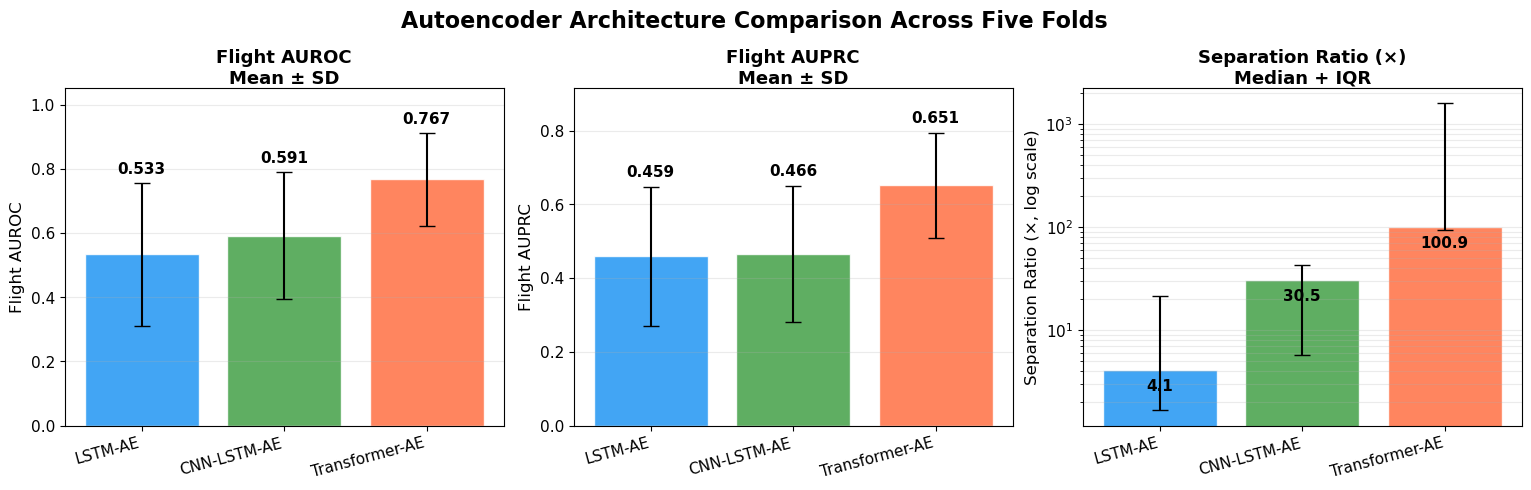

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15.5, 5.2)
)

fig.suptitle(
    "Autoencoder Architecture Comparison Across Five Folds",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

colors = ["#2196F3", "#43A047", "#FF7043"]
archs = ["LSTM-AE", "CNN-LSTM-AE", "Transformer-AE"]

# AUROC and AUPRC: mean ± standard deviation

metrics = [
    ("test_auroc", "Flight AUROC"),
    ("test_auprc", "Flight AUPRC")
]

for ax, (metric, ylabel) in zip(axes[:2], metrics):

    for i, arch in enumerate(archs):

        values = results_df.loc[
            results_df["architecture"] == arch,
            metric
        ]

        mean = values.mean()
        std = values.std()

        ax.bar(
            i,
            mean,
            yerr=std,
            color=colors[i],
            alpha=0.85,
            capsize=6,
            edgecolor="white",
            linewidth=1
        )

        ax.text(
            i,
            mean + std + 0.02,
            f"{mean:.3f}",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold"
        )

    ax.set_title(
        f"{ylabel}\nMean ± SD",
        fontsize=13,
        fontweight="bold",
        pad=3
    )

    ax.set_ylabel(
        ylabel,
        fontsize=12
    )

    ax.set_xticks(range(len(archs)))

    ax.set_xticklabels(
        archs,
        rotation=15,
        ha="right",
        fontsize=11
    )

    ax.tick_params(
        axis="y",
        labelsize=11
    )

    ax.grid(
        True,
        alpha=0.25,
        axis="y"
    )

    # Small amount of headroom for value labels
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.10)



# Separation ratio: median + IQR on log scale

ax = axes[2]

for i, arch in enumerate(archs):

    values = results_df.loc[
        results_df["architecture"] == arch,
        "test_sep_ratio"
    ].values

    median = np.median(values)
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)

    lower_error = median - q1
    upper_error = q3 - median

    ax.bar(
        i,
        median,
        yerr=np.array([[lower_error], [upper_error]]),
        color=colors[i],
        alpha=0.85,
        capsize=6,
        edgecolor="white",
        linewidth=1
    )

    # Place median value inside the bar
    ax.text(
        i,
        median / 1.45,
        f"{median:.1f}",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="black"
    )

ax.set_yscale("log")

ax.set_title(
    f"{ylabel}\n$\\mu \\pm \\sigma$",
    fontsize=13,
    fontweight="bold",
    pad=3
)

ax.set_ylabel(
    "Separation Ratio (×, log scale)",
    fontsize=12
)

ax.set_xticks(range(len(archs)))

ax.set_xticklabels(
    archs,
    rotation=15,
    ha="right",
    fontsize=11
)

ax.tick_params(
    axis="y",
    labelsize=11
)

ax.grid(
    True,
    alpha=0.25,
    axis="y",
    which="both"
)



fig.subplots_adjust(
    left=0.055,
    right=0.995,
    bottom=0.18,
    top=0.83,
    wspace=0.16
)

plt.savefig(
    PLOT_DIR / "architecture_comparison_thesis.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.02
)

plt.show()
plt.close()